# Rollout readiness: what breaks if Lumen enforces Santa today?

**Question:** if we switched every Mac from Santa *Monitor* to *Lockdown* mode, what would stop working, for whom, and what is the fix for each kind of breakage?

**Data:** the synthetic 3,000-device fleet from `generate_fleet.py` (four weeks of execution events). Every number below is **simulated**; the assumptions are in `README.md`.

**Two units, used throughout:**
- **Block incident:** one binary blocked on one device in one week. This is what a person feels ("my tool stopped working"), and the main measure.
- **Blocked executions:** every individual run attempt that would be denied. Useful for scale, but one broken tool can generate dozens.

Rates are per **100 devices per week**, so teams of different sizes compare fairly.

The answer, with the numbers, is in the last section.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd() / "analysis"
DATA, OUT = ROOT / "data", ROOT / "out"
OUT.mkdir(exist_ok=True)

ev = pd.read_csv(DATA / "execution_events.csv.gz", keep_default_na=False)
devices = pd.read_csv(DATA / "devices.csv")
N_DEV, WEEKS = len(devices), ev["week"].nunique()
DEV_WEEKS = N_DEV * WEEKS
team_devices = devices["team"].value_counts()
TEAMS = ["Engineering", "Research", "Sales", "Finance", "Support"]

# Chart style: thin marks, recessive axes (colors: categorical slots 1-5 of the reference palette)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "font.size": 11, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
})

def per100(rows):
    """Block incidents per 100 devices per week."""
    return 100 * len(rows) / DEV_WEEKS

print(f"{N_DEV:,} devices x {WEEKS} weeks = {DEV_WEEKS:,} device-weeks; {len(ev):,} event rows; "
      f"{ev['count'].sum():,} executions")

3,000 devices x 4 weeks = 12,000 device-weeks; 367,194 event rows; 10,702,183 executions


## 0. Starting point: rules we already have

Today, Lumen would only allowlist the **standard build** that IT installs on every Mac. Those vendors' Team IDs are the baseline rule set.

(The repo's real `santa/rules/global.toml` uses real Team IDs; the synthetic fleet uses made-up ones, so the baseline is taken from the data by app name.)

In [2]:
STANDARD = ["Google Chrome", "Slack", "Zoom", "1Password", "Microsoft Outlook",
            "Microsoft Teams", "Nudge", "Santa"]
baseline_ids = set(ev.loc[ev["file_name"].isin(STANDARD), "team_id"])
allowed0 = ev["team_id"].isin(baseline_ids)

total_exec = ev["count"].sum()
signed = ev["signed"] == "yes"
print(f"Baseline: {len(baseline_ids)} TEAMID rules")
print(f"Executions allowed today: {ev.loc[allowed0, 'count'].sum() / total_exec:.1%}")
print(f"Executions that are signed at all (the most any TEAMID/SIGNINGID rule set can reach): "
      f"{ev.loc[signed, 'count'].sum() / total_exec:.1%}")
print(f"If enforced today: {per100(ev[~allowed0]):.0f} block incidents per 100 devices per week")

Baseline: 8 TEAMID rules
Executions allowed today: 29.2%
Executions that are signed at all (the most any TEAMID/SIGNINGID rule set can reach): 82.9%
If enforced today: 2260 block incidents per 100 devices per week


## 1. Coverage: the smallest set of new rules

Every signed binary carries its vendor's **Team ID**. Each new rule allows one vendor (or one app), so the smallest set is found greedily: add the vendor that unblocks the most executions, then the next, until **99% of signed executions** are covered.

Unsigned binaries have no Team ID, so no Team ID or Signing ID rule can ever cover them; they're handled in sections 3 and 4.

**Rule type:** a vendor with several apps in the fleet gets a `TEAMID` rule; a vendor with a single app gets a narrower `SIGNINGID` rule (that app only).

In [3]:
cand = (ev[signed & ~allowed0]
        .groupby("team_id")
        .agg(executions=("count", "sum"), devices=("device_id", "nunique"),
             apps=("file_name", "nunique"), example_app=("file_name", "first"),
             signing_id=("signing_id", "first"))
        .sort_values("executions", ascending=False))

signed_exec = ev.loc[signed, "count"].sum()
base_signed = ev.loc[signed & allowed0, "count"].sum()
cand["signed_coverage"] = (base_signed + cand["executions"].cumsum()) / signed_exec
cand["all_coverage"] = (ev.loc[allowed0, "count"].sum() + cand["executions"].cumsum()) / total_exec
cand["rule_number"] = np.arange(1, len(cand) + 1)

TARGET = 0.99
k99 = int((cand["signed_coverage"] < TARGET).sum()) + 1
proposed = cand.head(k99).copy()
proposed["rule_type"] = np.where(proposed["apps"] > 1, "TEAMID", "SIGNINGID")
proposed["identifier"] = np.where(proposed["rule_type"] == "TEAMID", proposed.index, proposed["signing_id"])

print(f"Rules needed to reach {TARGET:.0%} of signed executions: {k99} "
      f"({(proposed['rule_type'] == 'TEAMID').sum()} TEAMID, {(proposed['rule_type'] == 'SIGNINGID').sum()} SIGNINGID)")
print(f"Signed vendors not yet allowlisted: {len(cand):,} (the long tail)")
print(f"With these rules, all executions allowed: {proposed['all_coverage'].iloc[-1]:.1%}")
for n in (10, 50, 100):
    if n <= len(cand):
        print(f"  first {n:>3} rules -> {cand['signed_coverage'].iloc[n-1]:.1%} of signed executions")
proposed[["example_app", "rule_type", "identifier", "devices", "executions"]].head(10)

Rules needed to reach 99% of signed executions: 655 (614 TEAMID, 41 SIGNINGID)
Signed vendors not yet allowlisted: 1,205 (the long tail)
With these rules, all executions allowed: 82.0%
  first  10 rules -> 57.7% of signed executions
  first  50 rules -> 84.3% of signed executions
  first 100 rules -> 93.3% of signed executions


,example_app,rule_type,identifier,devices,executions
team_id,,,,,
WT1Q3TMY4G,CommonApp 001,TEAMID,WT1Q3TMY4G,2540,513987
PYWSSBZRAD,CommonApp 004,TEAMID,PYWSSBZRAD,1370,217915
I65FDHJK1E,Docker Desktop,SIGNINGID,I65FDHJK1E:com.dockerdesktop,1553,203448
A9TGIQHG9J,Visual Studio Code,SIGNINGID,A9TGIQHG9J:com.visualstudiocode,1553,201567
5SOWOMQIGC,CommonApp 008,TEAMID,5SOWOMQIGC,1010,149441
72HPOEVB9O,JetBrains PyCharm,SIGNINGID,72HPOEVB9O:com.jetbrainspycharm,1090,142867
RSNVNQ65QD,Wireshark,SIGNINGID,RSNVNQ65QD:com.wireshark,1090,142591
D467KD6FLE,Postman,SIGNINGID,D467KD6FLE:com.postman,1090,141646
Q71N8MTZX2,JetBrains GoLand,SIGNINGID,Q71N8MTZX2:com.jetbrainsgoland,1090,141432


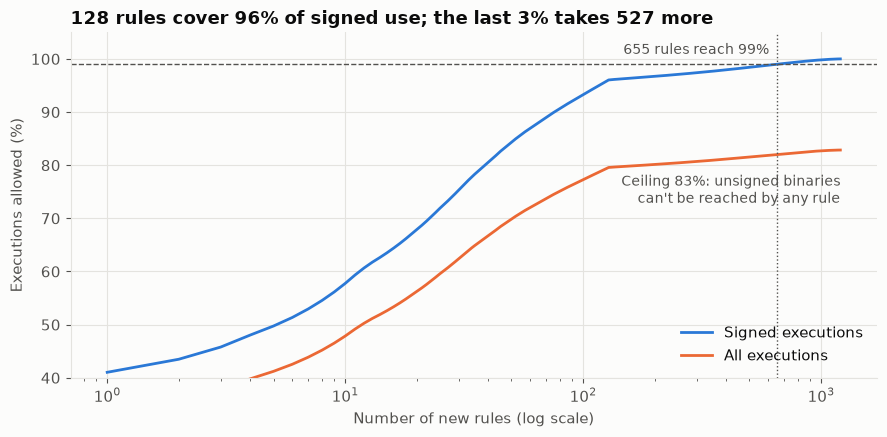

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = cand["rule_number"]
ax.plot(x, 100 * cand["signed_coverage"], color=SERIES[0], lw=2, label="Signed executions")
ax.plot(x, 100 * cand["all_coverage"], color=SERIES[1], lw=2, label="All executions")
ax.axhline(100 * TARGET, color=INK2, lw=1, ls="--")
ax.axvline(k99, color=INK2, lw=1, ls=":")
ax.annotate(f"{k99} rules reach 99%", (k99, 100 * TARGET), xytext=(-6, 5),
            textcoords="offset points", ha="right", va="bottom", color=INK2, fontsize=10)
ceiling = 100 * cand["all_coverage"].iloc[-1]
ax.annotate(f"Ceiling {ceiling:.0f}%: unsigned binaries\ncan't be reached by any rule",
            (x.iloc[-1], ceiling), xytext=(0, -38), textcoords="offset points",
            ha="right", color=INK2, fontsize=10)
knee = int((cand["signed_coverage"] < 0.96).sum()) + 1
ax.set_xscale("log")
ax.set_ylim(40, 105)
ax.set_xlabel("Number of new rules (log scale)")
ax.set_ylabel("Executions allowed (%)")
ax.set_title(f"{knee} rules cover 96% of signed use; the last 3% takes {k99 - knee} more")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

### Why Team ID rules, not hash rules

Apps update constantly, and each update is a new file hash. Below: if the same vendors had been allowlisted by **week-1 file hash** instead of Team ID, how much of their week-4 use would still match?

In [5]:
prop_ids = set(proposed.index) | baseline_ids
pv = ev[signed & ev["team_id"].isin(prop_ids)]
week1_hashes = set(pv.loc[pv["week"] == 1, "sha256"])
w4 = pv[pv["week"] == WEEKS]
hash_match = w4.loc[w4["sha256"].isin(week1_hashes), "count"].sum() / w4["count"].sum()
print(f"Week-{WEEKS} executions of allowlisted vendors still matched by week-1 hash rules: {hash_match:.1%}")
print(f"Matched by Team ID rules: 100.0%")
print(f"Hash rules needed to cover the same vendors over {WEEKS} weeks: {pv['sha256'].nunique():,} "
      f"(vs {len(prop_ids)} Team ID / Signing ID rules)")

Week-4 executions of allowlisted vendors still matched by week-1 hash rules: 41.6%
Matched by Team ID rules: 100.0%
Hash rules needed to cover the same vendors over 4 weeks: 3,430 (vs 663 Team ID / Signing ID rules)


## 2. Blast radius with the proposed rules

Now assume lockdown with the baseline **plus** the proposed rules. What is still blocked, and who feels it?

In [6]:
fleet_rules = baseline_ids | set(proposed.index)
blocked = ev[~ev["team_id"].isin(fleet_rules)].copy()

by_team = pd.DataFrame({
    "devices": team_devices.reindex(TEAMS),
    "block_incidents": blocked.groupby("team").size().reindex(TEAMS, fill_value=0),
    "blocked_executions": blocked.groupby("team")["count"].sum().reindex(TEAMS, fill_value=0),
})
by_team["incidents_per_100_dev_wk"] = 100 * by_team["block_incidents"] / (by_team["devices"] * WEEKS)
by_team["share_of_incidents"] = by_team["block_incidents"] / by_team["block_incidents"].sum()

B1 = per100(blocked)
print(f"Fleet-wide: {B1:.0f} block incidents per 100 devices per week "
      f"({100 * blocked['count'].sum() / DEV_WEEKS:,.0f} blocked executions)")
by_team.round({"incidents_per_100_dev_wk": 1, "share_of_incidents": 3})

Fleet-wide: 812 block incidents per 100 devices per week (16,031 blocked executions)


,devices,block_incidents,blocked_executions,incidents_per_100_dev_wk,share_of_incidents
team,,,,,
Engineering,1090,62821,1331360,1440.8,0.645
Research,463,19792,389177,1068.7,0.203
Sales,601,5761,74496,239.6,0.059
Finance,297,2619,32794,220.5,0.027
Support,549,6463,95872,294.3,0.066


## 3. Breakage classes

Group what's still blocked, using only what Santa actually reports (signature and path), the way a real team would. The generator's `category` column is used **only afterwards**, to check the grouping.

In [7]:
fleet_prev = ev.groupby("sha256")["device_id"].nunique()
p = blocked["path"]
is_signed = blocked["signed"] == "yes"
prevalent = blocked["sha256"].map(fleet_prev) >= 10

conditions = [
    is_signed,
    p.str.contains("/Downloads/"),
    p.str.contains("/go/bin/|/\\.cargo/bin/|/target/(?:debug|release)/", regex=True),
    p.str.startswith("/opt/homebrew/") | p.str.contains("/Cellar/"),
    p.str.startswith("/usr/local/bin/") & prevalent,
    p.str.startswith("/tmp/") | p.str.contains("/\\.", regex=True),
]
CLASSES = ["Signed app with no rule (long tail)", "Unsigned from a risky location",
           "Self-compiled developer build", "Package-manager tool (Homebrew)",
           "Unsigned internal tool", "Unsigned from a risky location"]
blocked["breakage_class"] = np.select(conditions, CLASSES, default="Unsigned, other")

ORDER = ["Self-compiled developer build", "Package-manager tool (Homebrew)", "Unsigned internal tool",
         "Signed app with no rule (long tail)", "Unsigned from a risky location", "Unsigned, other"]
classes = (blocked.groupby("breakage_class")
           .agg(block_incidents=("sha256", "size"), devices=("device_id", "nunique"),
                unique_binaries=("sha256", "nunique"), blocked_executions=("count", "sum"))
           .reindex([c for c in ORDER if c in set(blocked["breakage_class"])]))
classes["incidents_per_100_dev_wk"] = 100 * classes["block_incidents"] / DEV_WEEKS
classes["share"] = classes["block_incidents"] / classes["block_incidents"].sum()

expected = {"dev_build": "Self-compiled developer build", "homebrew": "Package-manager tool (Homebrew)",
            "internal_unsigned": "Unsigned internal tool", "rare": "Signed app with no rule (long tail)",
            "common": "Signed app with no rule (long tail)", "standard_app": "Signed app with no rule (long tail)",
            "suspicious": "Unsigned from a risky location"}
agree = (blocked["category"].map(expected) == blocked["breakage_class"]).mean()
print(f"Path/signature grouping agrees with the simulation's ground truth on {agree:.1%} of rows")
classes.round({"incidents_per_100_dev_wk": 1, "share": 3})

Path/signature grouping agrees with the simulation's ground truth on 100.0% of rows


,block_incidents,devices,unique_binaries,blocked_executions,incidents_per_100_dev_wk,share
breakage_class,,,,,,
Self-compiled developer build,9484,910,9484,395005,79.0,0.097
Package-manager tool (Homebrew),60908,1399,80,1247022,507.6,0.625
Unsigned internal tool,24164,2933,12,192972,201.4,0.248
Signed app with no rule (long tail),2892,1142,1427,88603,24.1,0.030
Unsigned from a risky location,8,8,5,97,0.1,0.000


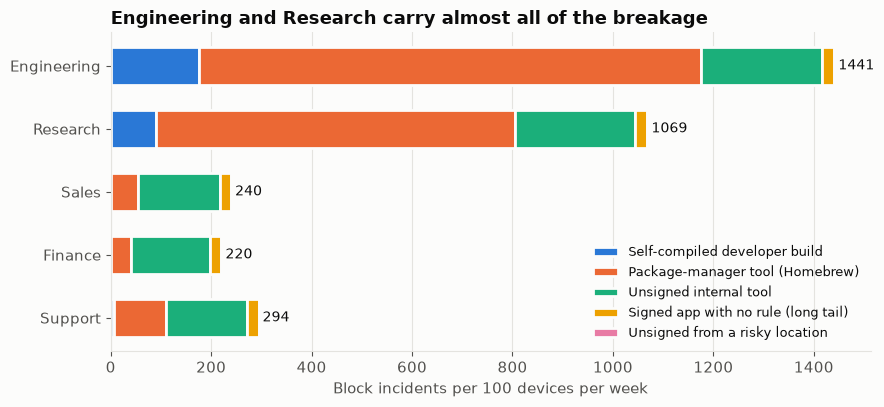

breakage_class,Self-compiled developer build,Package-manager tool (Homebrew),Unsigned internal tool,Signed app with no rule (long tail),Unsigned from a risky location
team,,,,,
Engineering,175.5,1000.8,239.0,25.4,0.1
Research,90.7,715.1,238.0,24.8,0.1
Sales,0.0,54.2,163.2,22.2,0.0
Finance,0.0,39.4,157.6,23.3,0.2
Support,6.9,102.7,161.2,23.4,0.0


In [8]:
plot_classes = list(classes.index)
team_class = (blocked.groupby(["team", "breakage_class"]).size().unstack(fill_value=0)
              .reindex(index=TEAMS, columns=plot_classes, fill_value=0))
team_rate = 100 * team_class.div(team_devices.reindex(TEAMS) * WEEKS, axis=0)

fig, ax = plt.subplots(figsize=(9, 4.2))
left = np.zeros(len(TEAMS))
colors = {c: SERIES[i % len(SERIES)] for i, c in enumerate(plot_classes)}
for c in plot_classes:
    vals = team_rate[c].values
    ax.barh(TEAMS, vals, left=left, color=colors[c], label=c, height=0.6,
            edgecolor="#fcfcfb", linewidth=2)
    left += vals
for i, total in enumerate(left):
    ax.text(total + 8, i, f"{total:.0f}", va="center", color=INK, fontsize=10)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Block incidents per 100 devices per week")
ax.set_title("Engineering and Research carry almost all of the breakage")
ax.legend(frameon=False, fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()
team_rate.round(1)

## 4. An alternative path for each class

| Class | Fix | How it works | Trade-off |
| --- | --- | --- | --- |
| Self-compiled developer build | **Transitive rules** | Mark compilers (`go`, `rustc`/`cargo`, `clang`) as `ALLOWLIST_COMPILER`; Santa then allows binaries those compilers produce on that Mac | Needs `EnableTransitiveRules`; only covers code built *after* the compiler rule exists |
| Package-manager tool (Homebrew) | **Approved-tool catalog** | Vet the tools engineers use; a sync job publishes `BINARY` rules for each new bottle hash | Rules must update when versions change (see lag test below). Rejected: allowlisting the whole `/opt/homebrew` path, because users can write there, so malware could too |
| Unsigned internal tool | **Sign them** | Sign Lumen's tools with the company Developer ID: one `TEAMID` rule covers every release. Until then, temporary `BINARY` exceptions via Project 3's bot, with an expiry | Requires a release-signing step in each tool's pipeline |
| Signed app with no rule | **Team-scoped rules** | Moroz serves per-machine rule files, so a vendor used by ≥3 devices in one team is allowed for that team only | Anything rarer becomes a self-service exception request |
| Unsigned from a risky location | **Keep blocked** | Downloads, /tmp and hidden folders are where malware runs from | These blocks are the point of lockdown |

In [9]:
TEAM_MIN_DEVICES = 3
APPROVED_MIN_DEVICES = 10

steps = [("Standard build only", per100(ev[~allowed0])), (f"{k99} fleet vendor rules", B1)]
remaining = blocked.copy()

remaining = remaining[remaining["breakage_class"] != "Self-compiled developer build"]
steps.append(("Transitive rules (developer builds)", per100(remaining)))

brew = remaining["breakage_class"] == "Package-manager tool (Homebrew)"
brew_prev = remaining[brew].groupby("file_name")["device_id"].nunique()
approved_tools = set(brew_prev[brew_prev >= APPROVED_MIN_DEVICES].index)
remaining = remaining[~(brew & remaining["file_name"].isin(approved_tools))]
steps.append(("Homebrew approved catalog", per100(remaining)))

remaining = remaining[remaining["breakage_class"] != "Unsigned internal tool"]
steps.append(("Sign internal tools", per100(remaining)))

sig = remaining["breakage_class"] == "Signed app with no rule (long tail)"
team_vendor_devices = remaining[sig].groupby(["team", "team_id"])["device_id"].nunique()
team_rules = set(team_vendor_devices[team_vendor_devices >= TEAM_MIN_DEVICES].index)
covered = sig & pd.Series(list(zip(remaining["team"], remaining["team_id"])), index=remaining.index).isin(team_rules)
remaining = remaining[~covered]
steps.append(("Team-scoped rules (long tail)", per100(remaining)))

residual = remaining.groupby("breakage_class").size()
print(f"Approved Homebrew tools: {len(approved_tools)}; team-scoped vendor rules: {len(team_rules)}")
print("Still blocked after every fix (incidents over 4 weeks):")
print(residual.to_string())

# Exception requests: each blocked (device, vendor) pair is roughly one request
exc = remaining[remaining["breakage_class"] == "Signed app with no rule (long tail)"]
exc_requests = exc.groupby(["device_id", "team_id"]).ngroups
risky = remaining[remaining["breakage_class"] == "Unsigned from a risky location"]
print(f"\nExpected exception requests: {exc_requests / WEEKS:.0f} per week "
      f"({100 * exc_requests / WEEKS / N_DEV:.1f} per 100 devices)")
print(f"Intended blocks (risky locations): {len(risky)} incidents on {risky['device_id'].nunique()} devices")

# Lag test: if the Homebrew catalog publishes new hashes one week late
bump_week = int(ev.loc[ev["category"] == "homebrew"].groupby("sha256")["week"].min().max())
lag_rows = blocked[(blocked["breakage_class"] == "Package-manager tool (Homebrew)") &
                   (blocked["week"] == bump_week) & blocked["file_name"].isin(approved_tools)]
lag_rate = 100 * len(lag_rows) / N_DEV
print(f"Catalog one week late on a version bump: {lag_rate:.0f} block incidents per 100 devices in that week")

Approved Homebrew tools: 40; team-scoped vendor rules: 57
Still blocked after every fix (incidents over 4 weeks):
breakage_class
Signed app with no rule (long tail)    2536
Unsigned from a risky location            8

Expected exception requests: 317 per week (10.6 per 100 devices)
Intended blocks (risky locations): 8 incidents on 8 devices


Catalog one week late on a version bump: 508 block incidents per 100 devices in that week


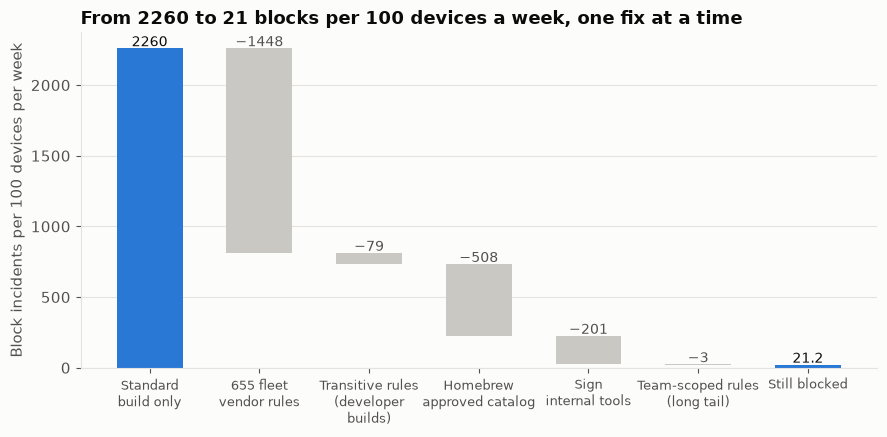

,after,incidents_per_100_dev_wk
0,Standard build only,2260.0
1,655 fleet vendor rules,812.1
2,Transitive rules (developer builds),733.1
3,Homebrew approved catalog,225.5
4,Sign internal tools,24.2
5,Team-scoped rules (long tail),21.2


In [10]:
labels = [s[0] for s in steps] + ["Still blocked"]
values = [s[1] for s in steps]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(0, values[0], color=SERIES[0], width=0.6)
ax.text(0, values[0] + 15, f"{values[0]:.0f}", ha="center", color=INK, fontsize=10)
for i in range(1, len(values)):
    drop = values[i - 1] - values[i]
    ax.bar(i, drop, bottom=values[i], color="#c9c8c2", width=0.6)
    ax.text(i, values[i - 1] + 15, f"−{drop:.0f}", ha="center", color=INK2, fontsize=10)
ax.bar(len(values), values[-1], color=SERIES[0], width=0.6)
ax.text(len(values), values[-1] + 15, f"{values[-1]:.1f}", ha="center", color=INK, fontsize=10)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels([l.replace(" (", "\n(").replace("rules ", "rules\n").replace(" vendor", "\nvendor").replace(" internal", "\ninternal").replace(" approved", "\napproved").replace(" build", "\nbuild") for l in labels], fontsize=9)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Block incidents per 100 devices per week")
ax.set_title(f"From {values[0]:.0f} to {values[-1]:.0f} blocks per 100 devices a week, one fix at a time")
plt.tight_layout()
plt.show()
pd.DataFrame(steps, columns=["after", "incidents_per_100_dev_wk"]).round(1)

## 5. The answer

In [11]:
eng_share = by_team.loc["Engineering", "share_of_incidents"]
dev_share = classes.loc["Self-compiled developer build", "share"] if "Self-compiled developer build" in classes.index else 0
B0 = per100(ev[~allowed0])
final = steps[-1][1]

summary = {
    "devices": N_DEV, "weeks": WEEKS,
    "incidents_per_100_dev_wk_today": round(B0, 1),
    "proposed_rules": k99, "signed_coverage_target": TARGET,
    "incidents_per_100_dev_wk_with_rules": round(B1, 1),
    "engineering_share": round(float(eng_share), 3),
    "developer_build_share": round(float(dev_share), 3),
    "incidents_per_100_dev_wk_after_all_fixes": round(final, 2),
    "exception_requests_per_week": round(exc_requests / WEEKS, 1),
    "intended_block_incidents": int(len(risky)),
    "hash_rule_match_after_4_weeks": round(float(hash_match), 3),
    "homebrew_lag_incidents_per_100_devices": round(lag_rate, 1),
    "steps": [{"after": a, "incidents_per_100_dev_wk": round(v, 2)} for a, v in steps],
}
(OUT / "readiness_summary.json").write_text(json.dumps(summary, indent=2))

rules = OUT / "proposed_rules.toml"
with open(rules, "w") as f:
    f.write("# SYNTHETIC Team IDs from the simulated fleet: for the analysis only, never merge into santa/rules/\n\n")
    for ident, r in proposed.iterrows():
        f.write(f'[[rules]]\nrule_type = "{r.rule_type}"\npolicy = "ALLOWLIST"\n'
                f'identifier = "{r.identifier}"\ncustom_msg = "{r.example_app} ({r.devices} devices)"\n\n')

print(f"Enforcing today would block {B0:.0f} binaries per 100 devices per week. "
      f"Adding {k99} vendor rules cuts that to {B1:.0f}, {eng_share:.0%} of it in Engineering. "
      f"Transitive rules alone remove {dev_share:.0%} of what's left; with the Homebrew catalog, "
      f"signed internal tools and team-scoped rules, it falls to {final:.1f} per 100 devices per week, "
      f"about {exc_requests / WEEKS:.0f} exception requests a week, plus {len(risky)} intended blocks of "
      f"binaries running from Downloads, /tmp or hidden folders.")
top = classes["share"].idxmax()
print("\nKey findings:")
print(f"- Biggest class: {top} ({classes.loc[top, 'share']:.0%} of incidents after fleet rules), not developer builds.")
print(f"- Hash rules are fragile: after {WEEKS} weeks only {hash_match:.0%} of allowlisted vendors' use still matched week-1 hashes.")
print(f"- The Homebrew catalog must publish rules before engineers upgrade: one week of lag = {lag_rate:.0f} blocks per 100 devices.")
print(f"- The long tail becomes exception load (~{exc_requests / WEEKS:.0f} requests a week): plan self-service approval for signed apps in Project 3's bot.")
print(f"\nWrote {OUT / 'readiness_summary.json'} and {rules}")

Enforcing today would block 2260 binaries per 100 devices per week. Adding 655 vendor rules cuts that to 812, 64% of it in Engineering. Transitive rules alone remove 10% of what's left; with the Homebrew catalog, signed internal tools and team-scoped rules, it falls to 21.2 per 100 devices per week, about 317 exception requests a week, plus 8 intended blocks of binaries running from Downloads, /tmp or hidden folders.

Key findings:
- Biggest class: Package-manager tool (Homebrew) (62% of incidents after fleet rules), not developer builds.
- Hash rules are fragile: after 4 weeks only 42% of allowlisted vendors' use still matched week-1 hashes.
- The Homebrew catalog must publish rules before engineers upgrade: one week of lag = 508 blocks per 100 devices.
- The long tail becomes exception load (~317 requests a week): plan self-service approval for signed apps in Project 3's bot.

Wrote /Users/yogi/corp-security-as-code/analysis/out/readiness_summary.json and /Users/yogi/corp-security-as

## Caveats

- All data is simulated (see `README.md`); the method, not the exact numbers, is the deliverable.
- Interpreted scripts aren't modelled: Santa evaluates the interpreter (python3, bash), not the script.
- Transitive rules are assumed to cover every developer build; in practice, builds from compilers outside the allowlist would remain.
- "Exception requests" assumes one request per blocked device-vendor pair; real users sometimes give up instead of asking, which hides breakage.